In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

In [2]:
root=Path("..")/"Experiment_Results"/"HasilEksperimenTahap2"/"Tahap2A"
sources = {
    "Crossover": root / "Crossover",
    "Population_500": root / "Population" / "500",
}
dataframes=[]
for source_name, folder in sources.items():
    csv_files = sorted(folder.rglob("*.csv"))
    print(f"{source_name}: ditemukan {len(csv_files)} file CSV")

    for csv_file in csv_files:
        df = pd.read_csv(csv_file)

        # Menyimpan asal data agar baris gabungan bisa dilacak
        df["source_group"] = source_name
        df["source_file"] = str(csv_file.relative_to(root))

        dataframes.append(df)
if dataframes:
    df_all=pd.concat(dataframes, ignore_index=True)
else:
    df_all=pd.DataFrame()
    print("Tidak ada file CSV yang berhasil dibaca.")

Crossover: ditemukan 36 file CSV
Population_500: ditemukan 12 file CSV


In [4]:
df_M03_crossover=df_all[df_all["model_id"]=="M03"].copy()
summary_M03_Crossover=df_M03_crossover.groupby(["grid_rows", "pc", "map_type"], as_index=False).agg(
    mean_cost=("best_cost", "mean"),
    best_run=("best_cost", "min"),
    worst_run=("best_cost", "max"),
    std_cost=("best_cost", "std"),
    total_runs=("best_cost", "count")
)
display(summary_M03_Crossover)

,grid_rows,pc,map_type,mean_cost,best_run,worst_run,std_cost,total_runs
0,10,0.80,Cluster,2.516667,2.500000,2.700000,0.046113,30
1,10,0.80,Maze,3.344444,3.333333,3.500000,0.042285,30
2,10,0.80,Random,2.614286,2.416667,2.857143,0.158651,60
3,10,0.85,Cluster,2.516667,2.500000,2.700000,0.046113,30
4,10,0.85,Maze,3.338889,3.333333,3.500000,0.030429,30
5,10,0.85,Random,2.604762,2.416667,2.857143,0.164415,60
6,10,0.90,Cluster,2.506667,2.500000,2.600000,0.025371,30
7,10,0.90,Maze,3.333333,3.333333,3.333333,0.000000,30
8,10,0.90,Random,2.609722,2.416667,2.928571,0.167315,60
9,10,0.95,Cluster,2.520000,2.500000,2.600000,0.040684,30


In [5]:
table_random=summary_M03_Crossover[summary_M03_Crossover["map_type"]=="Random"].sort_values("pc")
display(table_random)
table_cluster=summary_M03_Crossover[summary_M03_Crossover["map_type"]=="Cluster"].sort_values("pc")
display(table_cluster)
table_Maze=summary_M03_Crossover[summary_M03_Crossover["map_type"]=="Maze"].sort_values("pc")
display(table_Maze)

,grid_rows,pc,map_type,mean_cost,best_run,worst_run,std_cost,total_runs
2,10,0.80,Random,2.614286,2.416667,2.857143,0.158651,60
14,20,0.80,Random,6.248301,6.025000,6.487179,0.218088,60
26,40,0.80,Random,6.690272,6.532051,6.881250,0.106290,60
17,20,0.85,Random,6.247051,6.025000,6.487179,0.219164,60
29,40,0.85,Random,6.671728,6.519231,6.868750,0.116095,60
5,10,0.85,Random,2.604762,2.416667,2.857143,0.164415,60
20,20,0.90,Random,6.245791,6.025000,6.512821,0.219523,60
8,10,0.90,Random,2.609722,2.416667,2.928571,0.167315,60
32,40,0.90,Random,6.665264,6.512821,6.837500,0.104992,60
11,10,0.95,Random,2.599603,2.416667,2.857143,0.163465,60


,grid_rows,pc,map_type,mean_cost,best_run,worst_run,std_cost,total_runs
0,10,0.80,Cluster,2.516667,2.500000,2.700000,0.046113,30
12,20,0.80,Cluster,4.792793,4.783784,4.837838,0.016391,30
24,40,0.80,Cluster,5.483656,5.445161,5.606452,0.032079,30
15,20,0.85,Cluster,4.790090,4.783784,4.810811,0.011627,30
27,40,0.85,Cluster,5.487527,5.445161,5.645161,0.046637,30
3,10,0.85,Cluster,2.516667,2.500000,2.700000,0.046113,30
18,20,0.90,Cluster,4.786486,4.783784,4.810811,0.008247,30
6,10,0.90,Cluster,2.506667,2.500000,2.600000,0.025371,30
30,40,0.90,Cluster,5.474194,5.445161,5.529032,0.019447,30
9,10,0.95,Cluster,2.520000,2.500000,2.600000,0.040684,30


,grid_rows,pc,map_type,mean_cost,best_run,worst_run,std_cost,total_runs
1,10,0.80,Maze,3.344444,3.333333,3.500000,0.042285,30
13,20,0.80,Maze,6.808547,6.794872,6.846154,0.014650,30
25,40,0.80,Maze,6.875862,6.834483,6.958621,0.036538,30
16,20,0.85,Maze,6.805983,6.794872,6.846154,0.014572,30
28,40,0.85,Maze,6.879310,6.834483,6.965517,0.035984,30
4,10,0.85,Maze,3.338889,3.333333,3.500000,0.030429,30
19,20,0.90,Maze,6.808547,6.794872,6.846154,0.016123,30
7,10,0.90,Maze,3.333333,3.333333,3.333333,0.000000,30
31,40,0.90,Maze,6.869885,6.834483,6.972414,0.032182,30
10,10,0.95,Maze,3.344444,3.333333,3.500000,0.042285,30


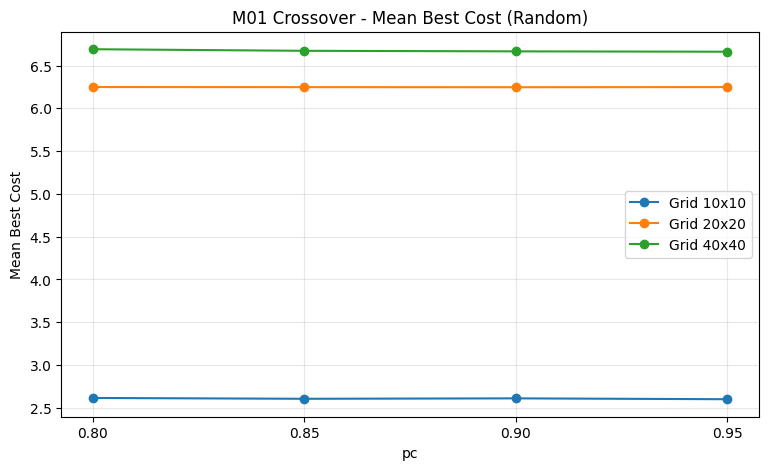

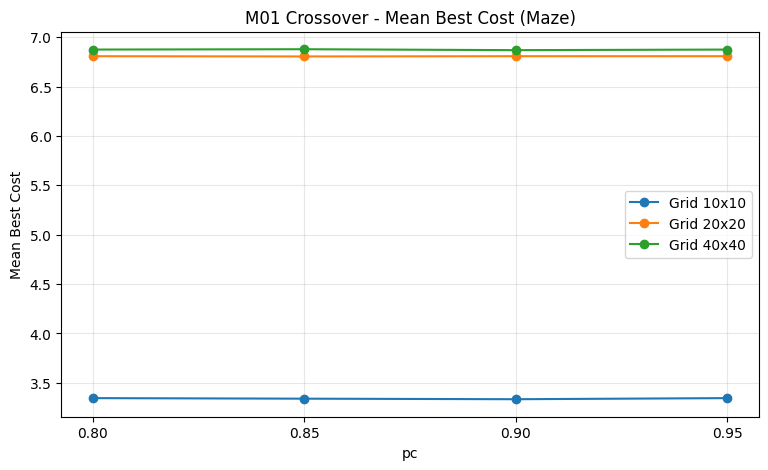

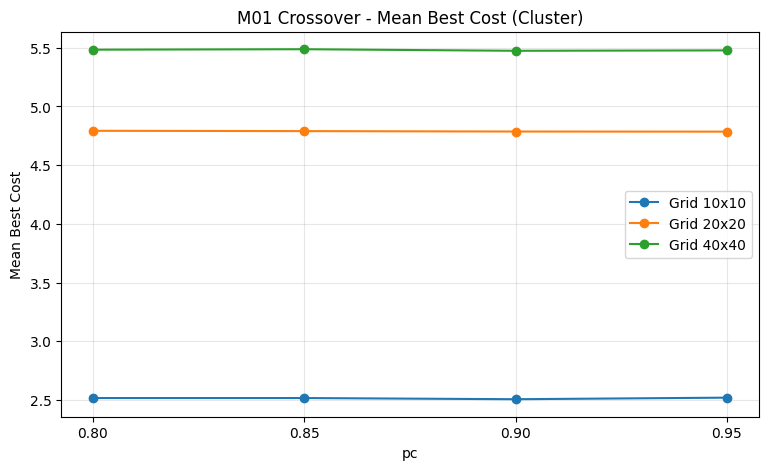

In [6]:
map_types = ["Random", "Maze", "Cluster"]

for map_type in map_types:
    data = summary_M03_Crossover[
        summary_M03_Crossover["map_type"] == map_type
    ].copy()

    plt.figure(figsize=(9, 5))

    for grid_rows in sorted(data["grid_rows"].unique()):
        data_size = (
            data[data["grid_rows"] == grid_rows]
            .sort_values("pc")
        )

        plt.plot(
            data_size["pc"],
            data_size["mean_cost"],
            marker="o",
            label=f"Grid {grid_rows}x{grid_rows}"
        )

    plt.title(f"M01 Crossover - Mean Best Cost ({map_type})")
    plt.xlabel("pc")
    plt.ylabel("Mean Best Cost")
    plt.xticks(sorted(data["pc"].unique()))
    plt.legend()
    plt.grid(True, alpha=0.3)

    plt.show()

In [7]:
summary_M03_Crossover["rank_mean_cost"] = (
    summary_M03_Crossover
    .groupby(["grid_rows", "map_type"])["mean_cost"]
    .rank(method="average", ascending=True)
)
avg_rank_M03 = (
    summary_M03_Crossover
    .groupby("pc", as_index=False)
    .agg(
        avg_rank_mean=("rank_mean_cost", "mean"),
        avg_mean_cost=("mean_cost", "mean"),
        avg_std_cost=("std_cost", "mean"),
        jumlah_kombinasi=("rank_mean_cost", "count")
    )
    .sort_values(["avg_mean_cost"])
)
display(avg_rank_M03)

,pc,avg_rank_mean,avg_mean_cost,avg_std_cost,jumlah_kombinasi
2,0.90,1.666667,5.033321,0.065911,9
3,0.95,2.333333,5.035632,0.072897,9
1,0.85,2.611111,5.038001,0.076115,9
0,0.80,3.388889,5.041648,0.074565,9


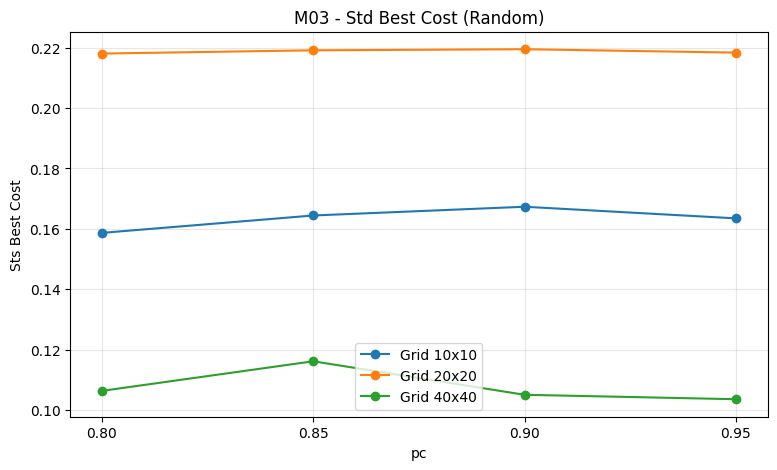

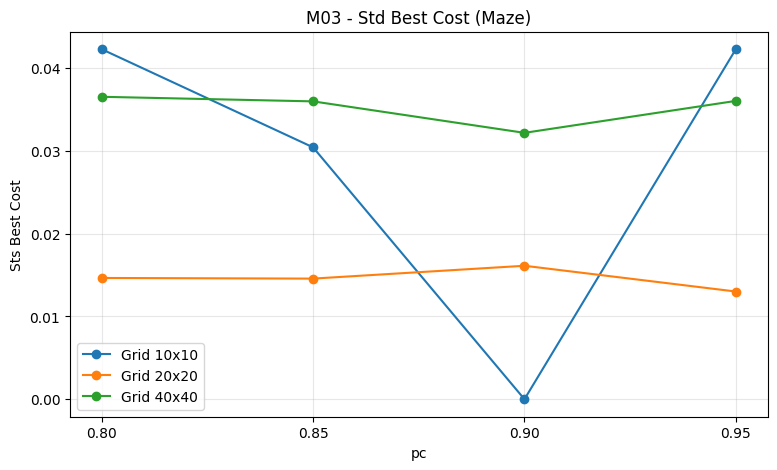

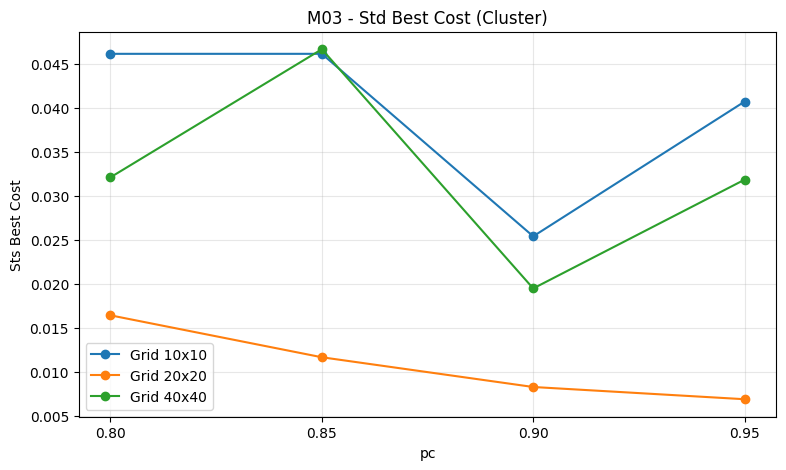

In [9]:
#std cost
map_types = ["Random", "Maze", "Cluster"]

for map_type in map_types:
    data = summary_M03_Crossover[
        summary_M03_Crossover["map_type"] == map_type
    ].copy()

    plt.figure(figsize=(9, 5))

    for grid_rows in sorted(data["grid_rows"].unique()):
        data_size = (
            data[data["grid_rows"] == grid_rows]
            .sort_values("pc")
        )

        plt.plot(
            data_size["pc"],
            data_size["std_cost"],
            marker="o",
            label=f"Grid {grid_rows}x{grid_rows}"
        )

    plt.title(f"M03 - Std Best Cost ({map_type})")
    plt.xlabel("pc")
    plt.ylabel("Sts Best Cost")
    plt.xticks(sorted(data["pc"].unique()))
    plt.legend()
    plt.grid(True, alpha=0.3)

    plt.show()

In [10]:
summary_M03_Crossover["rank_std_cost"] = (
    summary_M03_Crossover
    .groupby(["grid_rows", "map_type"])["std_cost"]
    .rank(method="average", ascending=True)
)

avg_rank_M03_std = (
    summary_M03_Crossover
    .groupby("pc", as_index=False)
    .agg(
        avg_rank_std=("rank_std_cost", "mean"),
        avg_std_cost=("std_cost", "mean"),
        jumlah_kombinasi=("rank_std_cost", "count")
    )
    .sort_values([ "avg_std_cost"])
)

print(avg_rank_M03_std)

     pc  avg_rank_std  avg_std_cost  jumlah_kombinasi
2  0.90      2.222222      0.065911                 9
3  0.95      2.000000      0.072897                 9
0  0.80      2.777778      0.074565                 9
1  0.85      3.000000      0.076115                 9


In [11]:
summary_M03_time_crossover=(df_M03_crossover.groupby(["grid_rows","pc", "map_type"], as_index=False).agg(
        mean_execTime=("execution_time_ms", "mean"),
        best_execTime=("execution_time_ms", "min"),
        worst_execTime=("execution_time_ms", "max"),
        std_Time=("execution_time_ms", "std"),
        total_runs=("execution_time_ms", "count")
    ))
display(summary_M03_time_crossover)

avg_time_by_population_m03 = (
    summary_M03_time_crossover
    .groupby("pc", as_index=False)
    .agg(
        avg_execTime=("mean_execTime", "mean"),
        avg_std_time=("std_Time", "mean"),
        jumlah_kombinasi=("mean_execTime", "count")
    )
    .sort_values("avg_execTime")
)
display(avg_time_by_population_m03)
summary_time_pivot = summary_M03_time_crossover.pivot(
    index=["grid_rows", "pc"],
    columns="map_type",
    values="mean_execTime"
)
display(summary_time_pivot)

avg_time_by_map = (
    summary_M03_time_crossover
    .groupby(["map_type", "pc"], as_index=False)
    .agg(
        avg_execTime=("mean_execTime", "mean"),
        avg_std_time=("std_Time", "mean"),
        jumlah_kombinasi=("mean_execTime", "count")
    )
    .sort_values(["map_type", "avg_execTime"])
)

print(avg_time_by_map)

,grid_rows,pc,map_type,mean_execTime,best_execTime,worst_execTime,std_Time,total_runs
0,10,0.80,Cluster,27.100000,12,69,16.731861,30
1,10,0.80,Maze,16.666667,10,30,4.830459,30
2,10,0.80,Random,22.033333,11,63,11.333117,60
3,10,0.85,Cluster,21.833333,9,37,7.534213,30
4,10,0.85,Maze,15.766667,9,24,3.766306,30
5,10,0.85,Random,20.500000,9,36,7.365748,60
6,10,0.90,Cluster,20.200000,11,30,4.693356,30
7,10,0.90,Maze,14.333333,9,22,3.032392,30
8,10,0.90,Random,21.883333,10,45,7.481257,60
9,10,0.95,Cluster,20.433333,11,32,5.544076,30


,pc,avg_execTime,avg_std_time,jumlah_kombinasi
1,0.85,560.738889,91.294230,9
0,0.80,580.135185,86.550775,9
2,0.90,606.109259,94.941415,9
3,0.95,607.703704,97.753924,9


map_type            Cluster         Maze       Random
grid_rows pc                                         
10        0.80    27.100000    16.666667    22.033333
          0.85    21.833333    15.766667    20.500000
          0.90    20.200000    14.333333    21.883333
          0.95    20.433333    17.600000    22.300000
20        0.80    99.600000    95.833333   109.550000
          0.85    97.266667   101.200000   105.916667
          0.90   103.400000   115.633333   119.000000
          0.95   101.333333   119.966667   101.033333
40        0.80  1518.233333  1783.400000  1548.800000
          0.85  1541.100000  1604.700000  1538.366667
          0.90  1999.233333  1424.766667  1636.533333
          0.95  1748.500000  1565.800000  1772.366667

   map_type    pc  avg_execTime  avg_std_time  jumlah_kombinasi
0   Cluster  0.80    548.311111     56.165132                 3
1   Cluster  0.85    553.400000     95.796279                 3
3   Cluster  0.95    623.422222     93.094589                 3
2   Cluster  0.90    707.611111    105.994033                 3
6      Maze  0.90    518.244444     83.784317                 3
7      Maze  0.95    567.788889     95.711981                 3
5      Maze  0.85    573.888889     84.215101                 3
4      Maze  0.80    631.966667    109.743854                 3
9    Random  0.85    554.927778     93.871311                 3
8    Random  0.80    560.127778     93.743340                 3
10   Random  0.90    592.472222     95.045896                 3
11   Random  0.95    631.900000    104.455201                 3
